### jieba分词模式
- 精确模式: 把句子最精确的切分开, 比较适合文本分析. 默认精确模式.
- 全模式: 把句子中所有可能成词的词都扫描出来, cut_all = True, 缺点: 速度快, 不能解决歧义
- 搜索引擎模式: 在精确模式的基础上, 对长词再进行切分, 提高召回率, jieba.cut_for_search
- paddle(d2l中提供的一种方式): 利用百度的paddlepaddle深度学习框架. 简单来说就是使用百度提供的分词模型. use_paddle=True.


jieba 是一个 Python 中文分词库，支持：
1. 精确模式分词。
2. 全模式分词。
3. 搜索引擎模式分词。
4. 自定义词典。
5. 关键词提取。
6. 词性标注。
7. 用户词典加载。
8. 中文文本预处理。
它主要解决的问题是：将连续的中文文本切分成具有一定语义的词语。

[jieba github](https://github.com/fxsjy/jieba)


In [1]:
import os

import jieba
print(jieba.__path__)
print(jieba.__version__)

['/Users/lxc20250729/lxc/code/llm-app-dev/llm02_ml_dl/.venv/lib/python3.12/site-packages/jieba']
0.42.1


In [16]:
# 1、精准模式（cut），
# 精确模式会尽可能将句子切分成最准确的词语，适合文本分析。
text = "jieba 是 Python 生态中非常经典的中文分词工具"
text = "我正在学习人工智能和大语言模型应用开发"
gen = jieba.cut(text, cut_all=False) # cut_all默认是False表示采用精确模式，使用True表示采用全模式
for t in gen:
    print(t, end='" > "')

我" > "正在" > "学习" > "人工智能" > "和" > "大" > "语言" > "模型" > "应用" > "开发" > "

In [18]:
# 2. 全模式（cut_all=True）
# 全模式会将句子中能够识别出来的词语尽可能全部切分出来。
# 注意：全模式可能产生大量重叠词语，因此通常不适合直接作为文本分类模型的输入。
fulls = jieba.lcut(text, cut_all=True)
for t in fulls:
    print(t, end='" > "')

# jieba 的 cut 的两种调用模式
# jieba.cut()：返回一个生成器（Generator）。
# jieba.lcut()：返回一个列表（List）。


我" > "正在" > "学习" > "人工" > "人工智能" > "智能" > "和" > "大" > "语言" > "模型" > "应用" > "开发" > "

In [21]:
# 3. 搜索引擎模式（cut_for_search）
# 搜索引擎模式是在精确模式的基础上，对较长的词语进一步拆分，增加可能匹配的搜索关键词。
res = jieba.lcut_for_search(text)
print(res)


['我', '正在', '学习', '人工', '智能', '人工智能', '和', '大', '语言', '模型', '应用', '开发']


In [22]:
# jieba 主要采用以下技术：
# 1. 基于前缀词典构建 Trie 树。
# 2. 基于词频和动态规划进行分词路径选择。
# 3. 使用 HMM 模型识别未登录词。



In [2]:
# 六、自定义词典（User Dictionary）


text = "我正在学习大语言模型LangChain和LangGraph框架以及Embedding向量数据库"
print(jieba.lcut(text)) # ['我', '正在', '学习', '大', '语言', '模型', 'LangChain', '和', 'LangGraph', '框架', '以及', 'Embedding', '向量', '数据库']

# 1. 动态添加词语：add_word
jieba.add_word("LangChain")
jieba.add_word("LangGraph")
jieba.add_word("向量数据库")
jieba.add_word("大语言模型")
print(jieba.lcut(text)) # ['我', '正在', '学习', '大语言模型', 'LangChain', '和', 'LangGraph', '框架', '以及', 'Embedding', '向量数据库']
# 还可以指定词频和磁性
jieba.add_word(
    "大语言模型",
    freq=10000,
    tag="n"
)
# 2. 删除词语：del_word
jieba.del_word("大语言")
# 3. 调整分词频率：suggest_freq
jieba.suggest_freq()


Building prefix dict from the default dictionary ...
Loading model from cache /var/folders/62/z650ynp965s9rqn86r5kl6kr0000gn/T/jieba.cache
Loading model cost 0.393 seconds.
Prefix dict has been built successfully.


['我', '正在', '学习', '大', '语言', '模型', 'LangChain', '和', 'LangGraph', '框架', '以及', 'Embedding', '向量', '数据库']
['我', '正在', '学习', '大语言模型', 'LangChain', '和', 'LangGraph', '框架', '以及', 'Embedding', '向量数据库']


In [2]:
# 使用自定义的词典。
# jieba分词词典结构有三列，分别是 “分词，词频，词性”

# 首先确定 jieba 分词的搜索路径
print(jieba.__path__) # /Users/lxc20250729/lxc/code/llm-app-dev/llm02_ml_dl/.venv/lib/python3.12/site-packages/jieba
# 进入 该路径创建一个自定义的字典 user_dict.txt
"""
echo "大语言 10000 n
大模型 10000 n
语言模型 10000 n" > user_dict.txt
"""

text = "所谓的大语言模型简单的说就是大模型加上语言模型"
print(jieba.lcut(text))

# 加载用户字典
jieba.load_userdict('/Users/lxc20250729/lxc/code/llm-app-dev/llm02_ml_dl/.venv/lib/python3.12/site-packages/jieba/user_dict.txt')
# 重新分词
print(jieba.lcut(text))


Building prefix dict from the default dictionary ...
Loading model from cache /var/folders/62/z650ynp965s9rqn86r5kl6kr0000gn/T/jieba.cache


['/Users/lxc20250729/lxc/code/llm-app-dev/llm02_ml_dl/.venv/lib/python3.12/site-packages/jieba']


Loading model cost 0.401 seconds.
Prefix dict has been built successfully.


['所谓', '的', '大', '语言', '模型', '简单', '的', '说', '就是', '大', '模型', '加上', '语言', '模型']
['所谓', '的', '大', '语言模型', '简单', '的', '说', '就是', '大模型', '加上', '语言模型']


In [11]:
# 关键词提取
#
from jieba import analyse
text = "人工智能正在改变软件开发行业，大语言模型可以帮助开发者提高开发效率，RAG 技术能够帮助大模型检索外部知识。"
# tf-idf
keywords = analyse.extract_tags(text, topK=3)
print(keywords)

keywords2 = analyse.extract_tags(text, topK=3, withWeight=True) # 获取关键字权重
for k, w in keywords2:
    print(k, w)
print("+"*50)
for k, w in analyse.tfidf(text, topK=5, withWeight=True):
    print(k, w)

print("+"*50)
# TextRank 算法
for k, w in analyse.textrank(text, topK=5, withWeight=True):
    print(k, w)



['语言模型', 'RAG', '大模型']
语言模型 0.597738375145
RAG 0.597738375145
大模型 0.597738375145
++++++++++++++++++++++++++++++++++++++++++++++++++
语言模型 0.597738375145
RAG 0.597738375145
大模型 0.597738375145
帮助 0.5809050240370001
开发者 0.550515294705
++++++++++++++++++++++++++++++++++++++++++++++++++
帮助 1.0
提高 0.5271551262511739
开发者 0.5258745504578761
效率 0.5150811214011988
检索 0.515056912685207


In [18]:
# 加载中文停用词
"""
echo "的
了
是
在
我
你
他
我们
他们
一个" > /Users/lxc20250729/lxc/code/llm-app-dev/llm02_ml_dl/.venv/lib/python3.12/site-packages/jieba/user_stopwords_zh_cn.txt
"""

import os
def load_stopwords(path) -> set[str]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"path 不存在该文件")
    with open(path, 'r', encoding='utf-8') as f:
        return set(line.strip() for line in f if line.strip())

stopwords_path = "/Users/lxc20250729/lxc/code/llm-app-dev/llm02_ml_dl/.venv/lib/python3.12/site-packages/jieba/user_stopwords_zh_cn.txt"
user_stopwords = load_stopwords(stopwords_path)
print(user_stopwords)

{'了', '是', '一个', '他们', '你', '我', '他', '在', '我们', '的'}


In [23]:
# 测试中文停用词

text = "我现在是一个正在学习自然语言处理和机器学习的人"
tokens = jieba.lcut(text)
print(tokens)

# 使用 中文停用词来过滤

filtered_words = [word for word in tokens if word not in user_stopwords]
print(filtered_words)

['我', '现在', '是', '一个', '正在', '学习', '自然语言', '处理', '和', '机器', '学习', '的', '人']
['现在', '正在', '学习', '自然语言', '处理', '和', '机器', '学习', '人']


In [24]:
# 十一、jieba 完整 API 汇总
# 前面已经学习了主要功能，这里汇总成一张表，方便以后查询。
# API	作用
# jieba.cut()	精确模式或全模式分词
# jieba.lcut()	返回列表形式的分词结果
# jieba.cut_for_search()	搜索引擎模式分词
# jieba.lcut_for_search()	返回列表形式的搜索模式结果
# jieba.add_word()	添加自定义词语
# jieba.del_word()	删除词语
# jieba.suggest_freq()	调整分词频率
# jieba.load_userdict()	加载自定义词典
# jieba.tokenize()	分词并返回字符位置
# jieba.posseg.cut()	词性标注
# jieba.analyse.extract_tags()	TF-IDF 关键词提取
# jieba.analyse.textrank()	TextRank 关键词提取
# jieba.analyse.set_stop_words()	设置关键词提取使用的停用词文件
# jieba.enable_parallel()	开启并行分词

输入一段中文文本，完成：
1. 中文分词。
2. 停用词过滤。
3. 词频统计。
4. 关键词提取。
5. 词性分析。
6. 高频词可视化。

In [26]:
import jieba
text = """人工智能正在改变软件开发行业。

大语言模型是人工智能领域的重要技术。
通过大语言模型，开发者可以构建智能应用。

RAG是一种检索增强生成技术。
RAG可以帮助大语言模型检索外部知识，
从而提高模型回答问题的准确性。

LangChain和LangGraph是常见的大模型应用开发框架。"""

In [32]:
# 1. 中文分词。
tokens = jieba.lcut(text)
print(len(tokens))
print(tokens)


70
['人工智能', '正在', '改变', '软件开发', '行业', '。', '\n', '\n', '大', '语言模型', '是', '人工智能', '领域', '的', '重要', '技术', '。', '\n', '通过', '大', '语言模型', '，', '开发者', '可以', '构建', '智能', '应用', '。', '\n', '\n', 'RAG', '是', '一种', '检索', '增强', '生成', '技术', '。', '\n', 'RAG', '可以', '帮助', '大', '语言模型', '检索', '外部', '知识', '，', '\n', '从而', '提高', '模型', '回答', '问题', '的', '准确性', '。', '\n', '\n', 'LangChain', '和', 'LangGraph', '是', '常见', '的', '大模型', '应用', '开发', '框架', '。']


In [33]:
# 2. 停用词过滤。
# 从网络上拉取一份别人整理好的中文停用词：https://github.com/yuanjie-ai/stopwords-zh/blob/master/stopwords/data/stopwords.zh.all.txt
# 将停用词放入项目路径：curl -o ./data/dl/tokenizer/stopwords.zh.all.txt https://github.com/yuanjie-ai/stopwords-zh/blob/master/stopwords/data/stopwords.zh.all.txt

# 加载停用词
stopwords_zh_all_path = "../../data/dl/tokenizer/stopwords.zh.all.txt"
stopwords_zh_all = load_stopwords(stopwords_zh_all_path)
filtered_stopword_tokens = [token for token in tokens if token not in stopwords_zh_all]

print(len(filtered_stopword_tokens))
print(filtered_stopword_tokens)


41
['人工智能', '改变', '软件开发', '行业', '\n', '\n', '语言模型', '人工智能', '领域', '技术', '\n', '语言模型', '开发者', '构建', '智能', '\n', '\n', 'RAG', '检索', '增强', '生成', '技术', '\n', 'RAG', '语言模型', '检索', '外部', '知识', '\n', '提高', '模型', '回答', '准确性', '\n', '\n', 'LangChain', 'LangGraph', '常见', '大模型', '开发', '框架']


In [34]:
# 3. 词频统计。
from collections import Counter
counter = Counter(filtered_stopword_tokens)
print(counter)

Counter({'\n': 9, '语言模型': 3, '人工智能': 2, '技术': 2, 'RAG': 2, '检索': 2, '改变': 1, '软件开发': 1, '行业': 1, '领域': 1, '开发者': 1, '构建': 1, '智能': 1, '增强': 1, '生成': 1, '外部': 1, '知识': 1, '提高': 1, '模型': 1, '回答': 1, '准确性': 1, 'LangChain': 1, 'LangGraph': 1, '常见': 1, '大模型': 1, '开发': 1, '框架': 1})


In [38]:
# 4. 关键词提取。
# jieba.analyse.extract_tags()	TF-IDF 关键词提取
# jieba.analyse.textrank()	TextRank 关键词提取
from jieba import analyse
print(analyse.extract_tags(text, topK=5, withWeight=True))
print(analyse.textrank(text, topK=5, withWeight=True))


[('语言模型', 0.8340535467139534), ('RAG', 0.5560356978093023), ('人工智能', 0.43990820444139533), ('检索', 0.4372496735651163), ('LangChain', 0.27801784890465114)]
[('语言模型', 1.0), ('应用', 0.8682150675723258), ('检索', 0.8640436111519427), ('人工智能', 0.7855318825617967), ('技术', 0.732855861444254)]


In [ ]:
# 5. 词性分析。


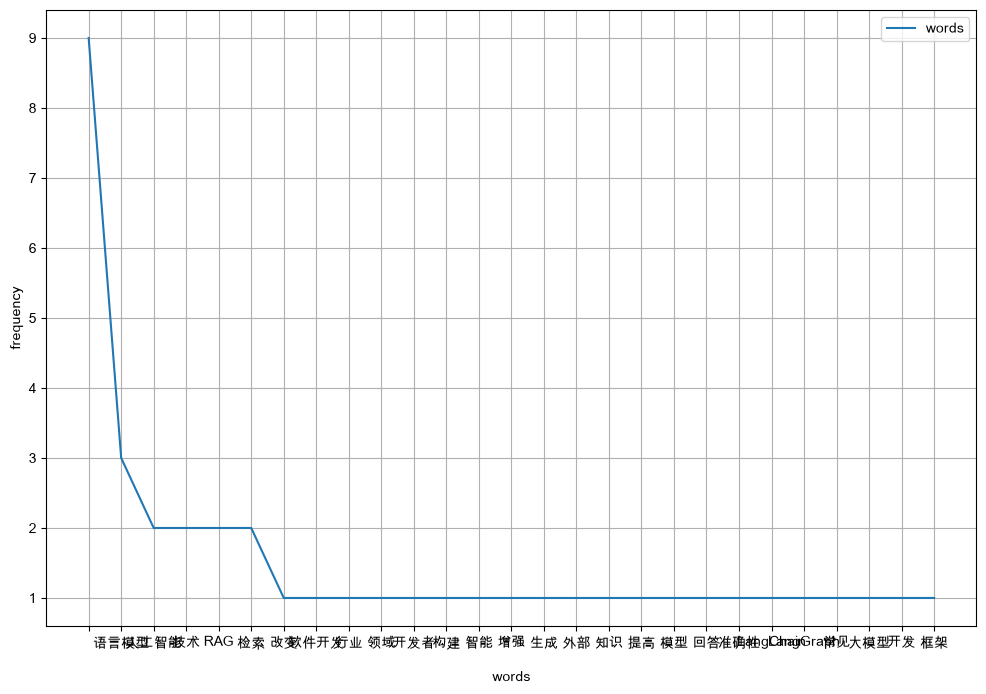

In [45]:
# 6. 高频词可视化。
import matplotlib.pyplot as plt


# 设置中文字体
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]

# 解决负号显示为方块的问题
plt.rcParams["axes.unicode_minus"] = False
# 先按词频从高到低拍个序
count_dict = sorted(counter.items(), key=lambda x: x[1], reverse=True)
words = []
freqs = []
for w, f in count_dict:
    words.append(w)
    freqs.append(f)

plt.figure(figsize=(12, 8))
plt.plot(words, freqs, label="words")
plt.xlabel("words")
plt.ylabel("frequency")
plt.legend()
plt.grid(True)
plt.show()